## 0 Imports and helpers

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from seismostats import Catalog
from seismostats.analysis import ClassicBValueEstimator, BPositiveBValueEstimator

In [2]:
# Helpers shared by the regional figures (Revision 2)
#  - window label and sliding-window N per window (Table S1)
#  - event marking (Reviewer 1, comments 1, 11d, 11f): panels (b), (d) and (f) mark the five largest events of
#    the window (open circles with date / magnitude labels in b, numbered dashed lines in d, numbered stars in f);
#    the M >= 6 (main text) / M >= 7 (SI) threshold is used only for the post-window stars in (f) (numbered dashed lines with date/magnitude labels; numbered stars);
#    one numbering per window (union of both sets, in time order); a window without an event above the
#    threshold highlights the five largest in (b) as well
#  - panel (a): probability densities of magnitudes and of positive magnitude differences with the GR (b-classical)
#    and b-positive lines, van der Elst (2021) Fig. 5 style (Reviewer 1, comments 2 and 11b)
#  - panel (b): magnitude vs event index with the local Mc (Reviewer 2, comment 4; Li et al. 2026 Fig. 4 style)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.patheffects import withStroke
from seismostats.analysis import BPositiveBValueEstimator, estimate_mc_maxc

FOLDER = os.path.basename(os.getcwd())[:3]
REGION_CODE = {'1.1': 'LMS', '1.2': 'XSH', '1.3': 'WYN', '1.4': 'XJ', '2hu': 'NCP', '3ti': 'NW'}[FOLDER]   # not 'REGION': the MCSENS/MCCOMP cells bind that name to a dict
CSV_FILE = {'1.1': 'longmenshan.csv', '1.2': 'xianshuihe.csv', '1.3': 'zuoxia.csv', '1.4': 'xiaojiang.csv',
            '2hu': 'region2_huabei.csv', '3ti': 'region3_tibet.csv'}[FOLDER]
# N of the sliding window (panel d and b-significant), Table S1; not named N_M, which the MCSENS/MCCOMP cells rebind
WINDOW_N = {'LMS_2006-2010': 500, 'LMS_2011-2016': 500, 'LMS_2016-2023': 100, 'LMS_1970-2023': 1000,
            'XSH_2022-2023': 300, 'XSH_1970-2023': 800, 'XSH_2008-2023': 800,
            'WYN_2020-2023': 500, 'WYN_2000-2023': 1000, 'WYN_1970-2023': 1000,
            'XJ_2016-2023': 150, 'XJ_1970-2023': 1500,
            'NCP_2008-2023': 500, 'NCP_1970-2023': 1200,
            'NW_2006-2023': 3000, 'NW_1970-2023': 8000}
# main-text windows (Figs. 4-10): highlight threshold M >= 6; all other windows (SI long-term figures): M >= 7
MAIN_WINDOWS = {'LMS_2006-2010', 'LMS_2011-2016', 'XSH_2022-2023', 'WYN_2020-2023', 'XJ_2016-2023',
                'NCP_2008-2023', 'NW_2006-2023'}
N_LARGEST = 5              # panels (b), (d), (f) mark every event with M >= the fifth-largest magnitude
# main-text analysis windows per region; shaded in panel (b) of the long-term (SI) figures only
ANALYSIS_WINDOWS = {
    'LMS': [('2006-01-01', '2011-01-01'), ('2011-01-01', '2017-01-01'), ('2016-01-01', '2024-01-01')],
    'XSH': [('2008-01-01', '2024-01-01'), ('2022-01-01', '2024-01-01')],
    'WYN': [('2000-01-01', '2024-01-01'), ('2020-01-01', '2024-01-01')],
    'XJ': [('2016-01-01', '2024-01-01')],
    'NCP': [('2008-01-01', '2024-01-01')],
    'NW': [('2006-01-01', '2024-01-01')],
}[REGION_CODE]
MIGNAN_BOUNDARIES = ('2001-01-01', '2008-01-01')      # catalog phases of Mignan et al. (2013), long-term panels only
C_EV, C_MC, C_STAR, C_POST = '#954e63', '#ce352e', '#ffd700', 'white'
C_HL = '#ce352e'           # panel (b): frame of the highlighted-event circles
C_GR, C_BPOS = '#1f77b4', '#d62728'                   # panel (a): magnitudes (classic-b blue) and positive differences (b-positive red)
CLASS_COLOURS = [(7.0, '#d62728', 'M7'), (6.0, '#ff7f0e', 'M6'), (5.0, '#2ca02c', 'M5')]   # panel (b) circles
HALO = [withStroke(linewidth=2.5, foreground='white')]   # keeps number labels legible on dark backgrounds


def window_label(cat):
    """e.g. 'LMS_2011-2016' (end year = year of the last event)."""
    return f'{REGION_CODE}_{cat.time.min().year}-{cat.time.max().year}'


def window_n(cat):
    """Sliding-window N: the value injected by the batch harness (N_M_RUN) or the Table S1 value."""
    return globals().get('N_M_RUN') or WINDOW_N[window_label(cat)]


def mark_threshold(cat):
    """Magnitude threshold of the highlighted events in panel (b): 6 for main-text windows, 7 for SI long windows."""
    return 6.0 if window_label(cat) in MAIN_WINDOWS else 7.0


def marked_events(mags, times, thr, n_largest=N_LARGEST):
    """Marking rule. Returns (numbers, thr_set, top_set):
    numbers  dict {positional index: number}, numbering in time order over the union of the two sets;
    thr_set  indices of events with M >= thr (circles in panel b), or top_set when there is none;
    top_set  indices of the n_largest largest events (dashed lines in panel d, stars in panel f).
    Indices refer to `mags`/`times` in whatever order they are passed."""
    mags = np.asarray(mags, float)
    times = np.asarray(times, dtype='datetime64[ns]')
    m_r = np.round(mags, 1)
    cutoff = np.sort(m_r)[-n_largest] if len(m_r) >= n_largest else m_r.min()
    top_set = np.where(m_r >= cutoff)[0]                # five largest, ties at the fifth magnitude included
    thr_set = np.where(mags >= thr)[0]
    if len(thr_set) == 0:
        thr_set = top_set
    ordered = top_set[np.argsort(times[top_set], kind='stable')]   # numbered in time order (panels b, d, f)
    numbers = {int(i): k for k, i in enumerate(ordered, 1)}
    numbers.update({int(i): None for i in thr_set if int(i) not in numbers})
    by_time = lambda s: np.asarray(sorted(s, key=lambda i: times[int(i)]), dtype=int)
    return numbers, by_time(thr_set), by_time(top_set)


def event_lines(mags, times, numbers, idx):
    t = pd.to_datetime(np.asarray(times))
    return [f'{numbers[int(i)]}  {t[i]:%Y-%m-%d}  M {float(mags[i]):.1f}' for i in idx]


LABEL_BOX = dict(boxstyle='round,pad=0.25', facecolor='white', alpha=0.85, edgecolor='0.6', lw=0.6)
LEADER = dict(arrowstyle='-', color='0.35', lw=0.6, shrinkA=0, shrinkB=3)


def _ring_candidates(radii=(5, 12, 22, 34, 48, 64, 82, 102)):
    """Offsets (points) around an anchor: 8 directions on growing rings, with matching alignment."""
    dirs = [(0, 1), (1, 1), (-1, 1), (1, 0), (-1, 0), (1, -1), (-1, -1), (0, -1)]   # upward first
    out = []
    for r in radii:
        for dx, dy in dirs:
            out.append((dx * r, dy * r, 'left' if dx > 0 else 'right' if dx < 0 else 'center',
                        'bottom' if dy > 0 else 'top' if dy < 0 else 'center'))
    return out


def _overlaps(a, b, pad=2.0):
    return not (a.x1 + pad < b.x0 or b.x1 + pad < a.x0 or a.y1 + pad < b.y0 or b.y1 + pad < a.y0)


def place_labels(ax, anchors, texts, candidates=None, xycoords='data', obstacles=(), marker_px=7,
                 region=None, leader_from=10, **text_kw):
    """Greedy, collision-free label placement. Call after the final layout (tight_layout / subplots_adjust).
    anchors   list of (x, y) in `xycoords`; texts: list of strings (same length)
    candidates list of (dx_pt, dy_pt, ha, va); default: rings around the anchor
    obstacles extra display-space Bboxes to avoid (e.g. legends); the anchors themselves are protected by a
              square of +/- marker_px pixels; region = (y0_frac, y1_frac) of the axes the labels must stay in.
    Labels further than `leader_from` points from their anchor get a thin leader line."""
    from matplotlib.transforms import Bbox
    from matplotlib.text import Text
    fig = ax.figure
    fig.canvas.draw()                                     # final limits / aspect before measuring
    r = fig.canvas.get_renderer()
    axbb = ax.get_window_extent(r)
    lo = axbb.y0 + (region[0] if region else 0) * axbb.height
    hi = axbb.y0 + (region[1] if region else 1) * axbb.height
    tr = ax.transData if xycoords == 'data' else mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
    placed = list(obstacles)
    if marker_px:                                          # protect the marked points themselves (not in panel d)
        for (x, y) in anchors:
            px, py = tr.transform((x, y))
            placed.append(Bbox.from_extents(px - marker_px, py - marker_px, px + marker_px, py + marker_px))
    cands = candidates or _ring_candidates()
    for (x, y), s in zip(anchors, texts):
        best = None
        for dx, dy, ha, va in cands:
            far = (dx * dx + dy * dy) ** 0.5 > leader_from
            ann = ax.annotate(s, (x, y), xycoords=xycoords, xytext=(dx, dy), textcoords='offset points',
                              ha=ha, va=va, zorder=8, bbox=LABEL_BOX, arrowprops=LEADER if far else None, **text_kw)
            ann.update_positions(r)
            bb = Text.get_window_extent(ann, r).padded(4)          # text + its box; the leader line is ignored
            inside = bb.x0 >= axbb.x0 and bb.x1 <= axbb.x1 and bb.y0 >= lo and bb.y1 <= hi
            hits = sum(_overlaps(bb, o) for o in placed)
            score = hits * 10 + (0 if inside else 100) + (dx * dx + dy * dy) ** 0.5 / 1000
            if best is None or score < best[0]:
                if best is not None:
                    best[1].remove()
                best = (score, ann, bb)
            else:
                ann.remove()
            if hits == 0 and inside:
                break
        placed.append(best[2])
    return placed


def mark_events_in_time(ax, times, mags, thr):
    """Panel (d): the five largest events as black dashed numbered lines. Returns the label jobs
    (anchor at the top of each line, text 'k  date  M x.x'; events less than 1 % of the time axis apart share
    one label) for place_event_labels_d(), which must run after the final layout."""
    mags = np.asarray(mags, float)
    t = pd.to_datetime(np.asarray(times))
    numbers, _, top_set = marked_events(mags, t.values, thr)
    xnum = mdates.date2num(t.to_pydatetime())
    x0, x1 = ax.get_xlim()
    groups = []
    for i in top_set:
        ax.axvline(xnum[i], color='k', ls='--', lw=1.1, zorder=4)
        line = f'{numbers[int(i)]}  {t[i]:%Y-%m-%d}  M {mags[i]:.1f}'
        if groups and xnum[i] - groups[-1]['x'] < 0.01 * (x1 - x0):
            groups[-1]['lines'].append(line)
        else:
            groups.append({'x': xnum[i], 'lines': [line]})
    return [((g['x'], 0.985), '\n'.join(g['lines'])) for g in groups]


def place_event_labels_d(ax, jobs):
    """Place the panel (d) labels in the head-room above the curves, beside their lines, without overlaps."""
    cands = []
    for k in range(12):                                    # successive heights below the top of the axes
        dy = -2 - 17 * k
        cands += [(4, dy, 'left', 'top'), (-4, dy, 'right', 'top')]
    obstacles = [ax.get_legend().get_window_extent(ax.figure.canvas.get_renderer())] if ax.get_legend() else []
    place_labels(ax, [a for a, _ in jobs], [t for _, t in jobs], candidates=cands, xycoords=('data', 'axes fraction'),
                 obstacles=obstacles, marker_px=0, region=(0.5, 1.0), leader_from=1e9, fontsize=10)


def plot_density_fmd(ax, mags, times, mc, delta_m, b_classical, b_classical_std, b_positive, b_positive_std, dmc=None):
    """Panel (a), van der Elst (2021) Fig. 5 style: probability density (per magnitude unit) of the magnitudes
    and of the positive magnitude differences between successive events above mc, with the GR line of slope
    b-classical (anchored at mc) and the exponential line of slope b-positive (anchored at dmc)."""
    dmc = delta_m if dmc is None else dmc
    mags = np.asarray(mags, float)
    mags = mags[~np.isnan(mags)]
    est = BPositiveBValueEstimator()
    est.calculate(mags, mc=mc, delta_m=delta_m, dmc=dmc, times=np.asarray(times))
    diffs = est.magnitudes                                        # positive differences >= dmc, binned

    def density(x):
        bins = np.round(np.arange(np.floor(x.min() / delta_m) * delta_m, x.max() + delta_m, delta_m), 6)
        counts = np.array([((x >= b - delta_m / 2) & (x < b + delta_m / 2)).sum() for b in bins])
        return bins, counts / (len(x) * delta_m)

    xm, pm = density(mags)
    xd, pd_ = density(diffs)
    ax.fill_between(xm, pm, 1e-9, step='mid', color=C_GR, alpha=0.35, lw=0, label='Magnitudes')
    ax.step(xm, pm, where='mid', color=C_GR, lw=1.0)
    ax.fill_between(xd, pd_, 1e-9, step='mid', color=C_BPOS, alpha=0.35, lw=0, label='Positive differences')
    ax.step(xd, pd_, where='mid', color=C_BPOS, lw=1.0)
    # model lines (per magnitude unit, same normalisation as the densities), drawn over the whole axis as in vdE Fig. 5
    frac_mc = (mags >= mc - delta_m / 2).mean()
    beta_c, beta_p = b_classical * np.log(10), b_positive * np.log(10)
    x = np.linspace(0, max(mags.max(), diffs.max()) + 0.3, 200)
    ax.plot(x, frac_mc * beta_c * 10 ** (-b_classical * (x - mc)), color='blue', lw=2.0, zorder=4,
            label=f'GR, b-classical = {b_classical:.2f} ($\\pm${b_classical_std:.2f})')
    ax.plot(x, beta_p * 10 ** (-b_positive * (x - dmc)), color='firebrick', lw=2.0, zorder=4,
            label=f'b-positive = {b_positive:.2f} ($\\pm${b_positive_std:.2f}), $dm_c$ = {dmc:.1f}')
    ax.axvline(mc, color='blue', ls='--', lw=1.0, zorder=3)
    ax.text(mc, 0.02, f' $m_c$ = {mc:.1f}', transform=mtransforms.blended_transform_factory(ax.transData, ax.transAxes),
            ha='left', va='bottom', fontsize=10, color='blue', path_effects=HALO)
    ax.axvline(dmc, color='firebrick', ls=':', lw=1.0, zorder=3)
    ax.text(dmc, 0.09, f' $dm_c$ = {dmc:.1f}', transform=mtransforms.blended_transform_factory(ax.transData, ax.transAxes),
            ha='left', va='bottom', fontsize=10, color='firebrick', path_effects=HALO)
    ax.set_yscale('log')
    top = max(pm.max(), pd_.max(), frac_mc * beta_c * 10 ** (b_classical * mc), beta_p * 10 ** (b_positive * dmc))
    ax.set_ylim(1e-6, top * 3)
    ax.set_xlim(-0.2, x.max())
    ax.set_xlabel('Magnitude  /  positive difference')
    ax.set_ylabel('Probability density')
    ax.grid(True, which='major', alpha=0.4)
    ax.legend(loc='upper right', frameon=True, edgecolor='black')
    return est


def post_window_events(cat, min_mag):
    """M >= min_mag events of the regional catalog that occurred after the analysed window (same CSV)."""
    full = pd.read_csv(CSV_FILE, sep=',', usecols=['year', 'month', 'day', 'hour', 'minute', 'second',
                                                   'latitude', 'longitude', 'magnitude'])
    full['time'] = pd.to_datetime(full[['year', 'month', 'day', 'hour', 'minute', 'second']])
    sel = (full['time'] > cat.time.max()) & (full['magnitude'] >= min_mag)
    return full.loc[sel, ['time', 'longitude', 'latitude', 'magnitude']].sort_values('time')


def class_colour(m):
    for lo, col, _ in CLASS_COLOURS:
        if m >= lo:
            return col
    return '0.3'


def plot_mags_vs_index(ax, cat, mc, n_m, thr, windows=(), step=None, seed=0):
    """Magnitude of every event against its index in time order.
    Local Mc = MAXC + 0.2 in sliding windows of n_m events, plotted at the last event of each window
    (same convention as panel d). Magnitudes are jittered within their 0.1 bin for display only.
    Events with M >= thr (or the five largest when there is none) as open circles coloured by magnitude class
    (van der Elst 2021, Fig. 4), numbered as in panel (d).
    For windows that start before 2001 the Mignan et al. (2013) catalog-phase boundaries are drawn."""
    srt = np.argsort(cat.time.values, kind='stable')
    mags = cat.magnitude.values[srt]
    times = cat.time.values[srt]
    idx = np.arange(len(mags))
    step = step or max(1, n_m // 10)
    ends = np.arange(n_m, len(mags) + 1, step)
    mc_loc = np.array([estimate_mc_maxc(mags[e - n_m:e], fmd_bin=0.1)[0] for e in ends])
    jit = np.random.default_rng(seed).uniform(-0.05, 0.05, len(mags))
    size = 1 + 2.5 ** (mags - 2)

    for a, b in windows:                      # shaded analysis windows (long-term figures)
        ia, ib = np.searchsorted(times, np.datetime64(a)), np.searchsorted(times, np.datetime64(b))
        inside = np.datetime64(a) >= times[0] and np.datetime64(b) <= times[-1] + np.timedelta64(1, 'D')
        if inside and (ia > 0 or ib < len(mags)):   # shade only windows strictly inside the plotted catalog
            ax.axvspan(ia, ib, color='0.5', alpha=0.08, lw=0)
    if times[0] < np.datetime64(MIGNAN_BOUNDARIES[0]):
        for k, bnd in enumerate(MIGNAN_BOUNDARIES):
            ib = np.searchsorted(times, np.datetime64(bnd))
            if 0 < ib < len(mags):
                ax.axvline(ib, color='0.4', ls='-.', lw=0.9, zorder=3)
                ax.text(ib, 0.01 + 0.05 * k, f' {bnd[:4]}', transform=mtransforms.blended_transform_factory(ax.transData, ax.transAxes),
                        ha='left', va='bottom', fontsize=10, color='0.3', path_effects=HALO)
    ax.scatter(idx, mags + jit, s=size, c=C_EV, alpha=0.25, linewidths=0, rasterized=True)
    ax.axhline(mc, color='k', ls='--', lw=1)
    ax.step(ends - 1, mc_loc, where='post', color=C_MC, lw=1.6)
    numbers, _, top_set = marked_events(mags, times, thr)   # same five events as panels (d) and (f)
    thr_set = top_set
    ax.scatter(thr_set, mags[thr_set], s=60, marker='o', fc='none', ec=C_HL, lw=1.4, zorder=6)
    t = pd.to_datetime(times)
    jobs = []                                              # one label per day: 'date' / 'M x.x[, y.y]'
    for i in thr_set:
        day = f'{t[i]:%Y-%m-%d}'
        if jobs and jobs[-1]['day'] == day:
            jobs[-1]['m'].append(mags[i])
            if mags[i] > mags[jobs[-1]['i']]:
                jobs[-1]['i'] = i
        else:
            jobs.append({'day': day, 'i': i, 'm': [mags[i]]})
    ax._event_label_jobs = [((j['i'], mags[j['i']]), j['day'] + '\n' + 'M ' + ', '.join(f'{m:.1f}' for m in j['m']))
                            for j in jobs]
    ax.set_xlim(0, len(mags))
    n_lab = len(getattr(ax, '_event_label_jobs', []))
    ax.set_ylim(mags.min() - 0.3, mags.max() + 1.0 + 0.3 * n_lab)   # head-room grows with the number of labels
    ax.set_xlabel('Event index')
    ax.set_ylabel('Magnitude')
    ax.grid(True, color='0.9', lw=0.6)
    ax.set_axisbelow(True)
    handles = [Line2D([], [], marker='o', ls='', mfc=C_EV, mec='none', ms=5, alpha=0.6, label='events'),
               Line2D([], [], color=C_MC, lw=1.6, label=f'local $m_c$ (MAXC+0.2, N = {n_m})'),
               Line2D([], [], color='k', ls='--', lw=1, label=f'$m_c$ used = {mc:.1f}')]
    fallback = not (mags >= thr).any()
    hl_label = 'five largest events' if fallback else f'M $\\geq$ {thr:.0f}'
    handles.append(Line2D([], [], marker='o', ls='', mfc='none', mec=C_HL, mew=1.4, ms=7, label=hl_label))
    # no legend in panel (b): symbols are explained in the figure caption
    return ax


def place_event_labels_b(ax):
    """Place the panel (b) date / magnitude labels (after the final layout)."""
    jobs = getattr(ax, '_event_label_jobs', [])
    if jobs:
        place_labels(ax, [a for a, _ in jobs], [t for _, t in jobs], fontsize=10, linespacing=1.0)


def event_label_text(evs):
    """Label for one or several events at (nearly) the same place: 'date / M x.x' as in panel (b);
    several days give one line per day."""
    days = {}
    for t, m in evs:
        days.setdefault(f'{pd.Timestamp(t):%Y-%m-%d}', []).append(m)
    if len(days) == 1:
        (d, ms), = days.items()
        return d + '\n' + 'M ' + ', '.join(f'{m:.1f}' for m in ms)
    return '\n'.join(f'{d}  M ' + ', '.join(f'{m:.1f}' for m in ms) for d, ms in days.items())


def place_event_labels_f(ax, anchors, events, merge_px=12):
    """Place the panel (f) date / magnitude labels (after the final layout). events: list of (time, magnitude)
    per star. Stars closer than merge_px pixels on the page share one label."""
    fig = ax.figure
    fig.canvas.draw()
    pix = ax.transData.transform(np.asarray(anchors, float)) if len(anchors) else np.zeros((0, 2))
    groups = []
    for k, p in enumerate(pix):
        for g in groups:
            if np.hypot(*(pix[g[0]] - p)) < merge_px:
                g.append(k); break
        else:
            groups.append([k])
    g_anchors = [tuple(np.mean([anchors[k] for k in g], axis=0)) for g in groups]
    g_texts = [event_label_text(sorted((events[k] for k in g), key=lambda e: pd.Timestamp(e[0]))) for g in groups]
    obstacles = [ax.get_legend().get_window_extent(fig.canvas.get_renderer())] if ax.get_legend() else []
    place_labels(ax, g_anchors, g_texts, obstacles=obstacles, marker_px=8, fontsize=10, linespacing=1.0)


def marked_cutoff(mags, n_largest=N_LARGEST):
    """Magnitude of the fifth-largest event (rounded to 0.1): every event at or above it is marked."""
    m_r = np.round(np.asarray(mags, float), 1)
    return float(np.sort(m_r)[-n_largest]) if len(m_r) >= n_largest else float(m_r.min())


## 1 Catalog (regional CSV, time window of this figure)

In [3]:
data = pd.read_csv(
    'zuoxia.csv',
    sep=',',
    usecols=['year', 'month', 'day', 'hour', 'minute', 'second','latitude', 'longitude','depth', 'mag_type', 'magnitude']
    # delim_whitespace=True,
    # usecols=['lat', 'lon', 'depth', 'year', 'month', 'day', 'hour', 'minute', 'second', 'magnitude']
)

data['time'] = pd.to_datetime(data[['year', 'month', 'day', 'hour', 'minute', 'second']])
data = data[data['time']>='2020-01-01 00:00:00']
data = data[data['time']<'2024-01-01 00:00:00']

data = data[['longitude', 'latitude', 'depth', 'time', 'magnitude']]
# print(data.isnull().sum())
cat = Catalog(data)

# cat
cat.tail()

,longitude,latitude,depth,time,magnitude
165939,99.866,26.098,16,2023-08-13 03:35:39.310,1.2
165940,98.937,24.587,20,2023-08-13 10:04:05.730,3.3
165941,100.884,27.376,12,2023-08-13 11:56:56.930,1.8
165942,100.128,25.937,19,2023-08-13 13:01:01.530,1.6
165943,99.594,25.448,21,2023-08-13 20:49:12.980,1.6


## 2 FMD, magnitude of completeness (MAXC + 0.2) and b-values

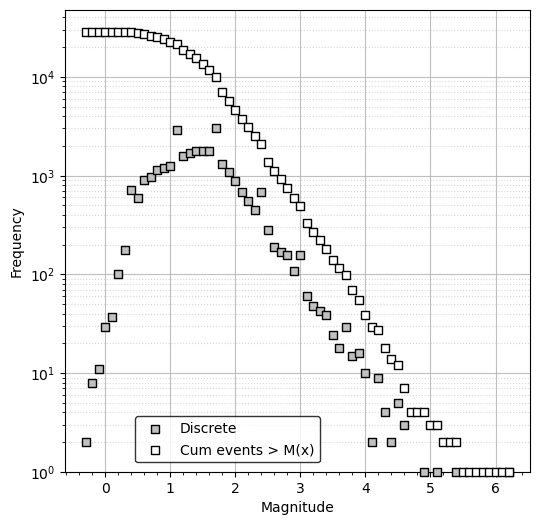

In [4]:
# It is *highly* recommended to bin magnitudes to the catalogue precision before plotting
cat.bin_magnitudes(delta_m=0.1, inplace=True)

# Plot FMD
ax = plt.subplots(figsize=(6, 6))[1]


# non-cumulative frequency-magnitude distribution with different bin sizes
cat.plot_fmd(fmd_bin=0.1, ax=ax, label="Discrete")
# cumulative frequency-magnitude distribution
cat.plot_cum_fmd(fmd_bin=0.1, ax=ax, grid=True)

plt.show()

In [5]:
# Maximum Curvature (MAXC)

# For this method a magnitude discretisation has to be selected by the user with `fmd_bin`. 
# This binning might be different from the binning of the catalog; the optimal value depends on the data. 
mc_maxc, _= cat.estimate_mc_maxc(fmd_bin=0.1)

# By using the a method to estimate the magnitude of completeness, the catalog is automatically updated with the estimated Mc value.
print(f'Estimated Mc using MAXC: {mc_maxc}')
print(f'Mc (currently set catalog attribute): {cat.mc}')

Estimated Mc using MAXC: 1.9
Mc (currently set catalog attribute): 1.9


In [6]:
b_estimator = cat.estimate_b(mc=mc_maxc)
b_classical = b_estimator.b_value
b_classical_std = b_estimator.std
# The calculated b-value is stored in cat.b_value, but the estimator object contains more information:
print('Classical b-value', round(b_classical,3))
print('Standard deviation', round(b_classical_std,2))
print('Number of events used', b_estimator.n)

Classical b-value 0.964
Standard deviation 0.01
Number of events used 5703


In [7]:
from seismostats.analysis import BPositiveBValueEstimator
b_estimator = cat.estimate_b(mc=mc_maxc,method =BPositiveBValueEstimator)
b_positive = b_estimator.b_value
b_positive_std = b_estimator.std
print("b-positive:",round(b_positive,3 ))
print("std:",round(b_positive_std,2))

b-positive: 1.055
std: 0.02


## 3 Temporal analysis: b-significant test (Table S1), Mc sensitivity (Table S5, Fig. S17), Mc estimators (Table S6)

In [8]:
from seismostats.analysis import ClassicBValueEstimator, BPositiveBValueEstimator, b_significant_1D
# Is the b-value calculated with 100 events above completeness constant over time?
p_threshold = 0.05
mc = mc_maxc # chosen magnitude of completeness
delta_m = cat.delta_m # binning of the magnitudes
times = cat.time 
mags = cat.magnitude
n_m = window_n(cat)   # N of Table S1 (or N_M_RUN from the batch harness)
p_classic, mac, mu_mac, std_mac = b_significant_1D(mags, mc, delta_m, times, n_m, method= ClassicBValueEstimator)
p_positive, mac, mu_mac, std_mac = b_significant_1D(mags, mc, delta_m, times, n_m, method= BPositiveBValueEstimator)

print('The p-classic of a constant b-value hypothesis is {:.2f}'.format(p_classic))
print('The p-positive of a constant b-value hypothesis is {:.2f}'.format(p_positive))

if p_classic < p_threshold:
    print('This is smaller than our threshold of {:.2f}. Therefore, we can reject the null-hypothesis'.format(p_threshold))
else:   
    print('This is significantly larger than our threshold of {:.2f}. Therefore, we cannot reject the null-hypothesis'.format(p_threshold))


/Users/chouyuhin/miniconda3/envs/gmtenv/lib/python3.12/site-packages/seismostats/analysis/b_significant.py:367: UserWarning: The number of subsamples is less than 25. The normality assumption of the autocorrelation might not be valid.
  warnings.warn(


The p-classic of a constant b-value hypothesis is 0.04
The p-positive of a constant b-value hypothesis is 0.02
This is smaller than our threshold of 0.05. Therefore, we can reject the null-hypothesis


/Users/chouyuhin/miniconda3/envs/gmtenv/lib/python3.12/site-packages/seismostats/analysis/b_significant.py:367: UserWarning: The number of subsamples is less than 25. The normality assumption of the autocorrelation might not be valid.
  warnings.warn(


       window    t_start      t_end  n_m  mc  chosen  n_classical  b_classical  b_classical_std  n_positive  b_positive  b_positive_std  p_classical  p_positive  n_subsamples
WYN_2020-2023 2020-01-01 2023-08-13  500 1.7   False        10037        1.077            0.011        4227       1.025           0.015        0.043       0.032          20.1
WYN_2020-2023 2020-01-01 2023-08-13  500 1.9    True         5703        0.964            0.012        2477       1.055           0.021        0.035       0.023          11.4
WYN_2020-2023 2020-01-01 2023-08-13  500 2.1   False         3748        0.994            0.016        1626       1.104           0.027        0.041       0.042           7.5
WYN_2020-2023 2020-01-01 2023-08-13  500 2.3   False         2516        1.073            0.022        1087       1.118           0.034        0.072       0.053           5.0


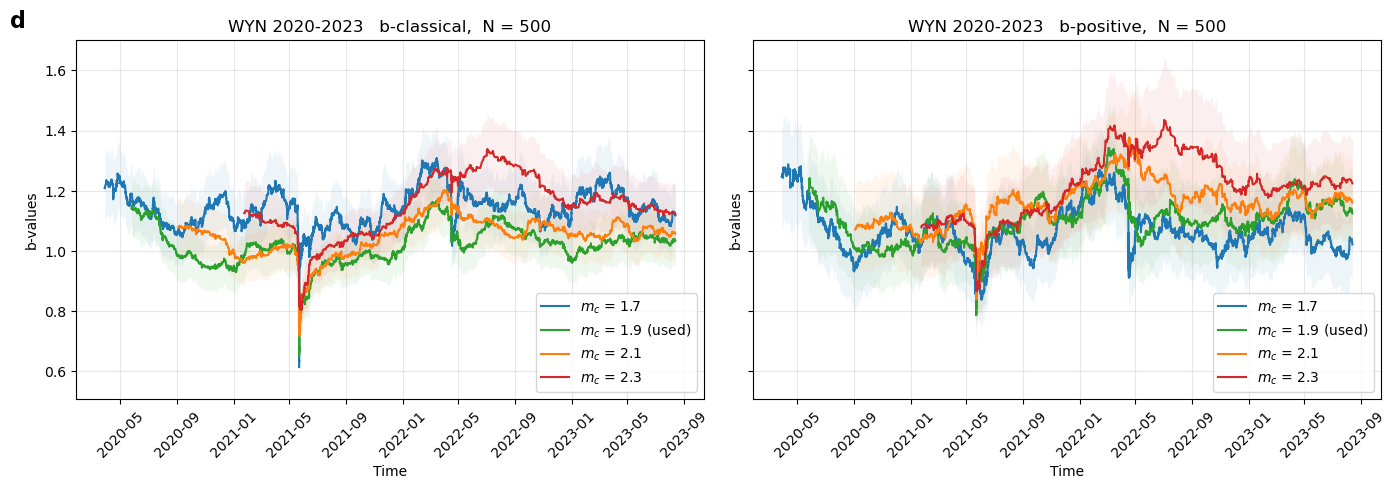

In [9]:
# MCSENS: stability of the temporal analysis to the choice of Mc (Reviewer 1, comment 2) -> Table S5 / Figure S17
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from seismostats.analysis import ClassicBValueEstimator, BPositiveBValueEstimator, b_significant_1D
from seismostats.plots import plot_b_series_constant_nm
warnings.simplefilter('once')

REGION = {'1.1': 'LMS', '1.2': 'XSH', '1.3': 'WYN', '1.4': 'XJ', '2hu': 'NCP', '3ti': 'NW'}
region = REGION[os.path.basename(os.getcwd())[:3]]
t_start, t_end = cat.time.min(), cat.time.max()
label = f'{region}_{t_start.year}-{t_end.year}'
N_M = {'LMS_2006-2010': 500, 'LMS_2011-2016': 500, 'XSH_2022-2023': 400, 'WYN_2020-2023': 500,
       'XJ_2016-2023': 150, 'NCP_2008-2023': 500, 'NW_2006-2023': 3000}
n_m_sens = N_M[label]

delta_m = cat.delta_m
srt = np.argsort(cat.time.values)
mags_s = cat.magnitude.values[srt]
times_s = cat.time.values[srt]
mc_chosen = round(float(mc_maxc), 1)
mcs_test = np.round(mc_chosen + np.array([-0.2, 0.0, 0.2, 0.4]), 1)

rows = []
for mc_i in mcs_test:
    est_c = ClassicBValueEstimator(); est_c.calculate(mags_s, mc=mc_i, delta_m=delta_m)
    est_p = BPositiveBValueEstimator(); est_p.calculate(mags_s, mc=mc_i, delta_m=delta_m, dmc=delta_m, times=times_s)
    p_c = b_significant_1D(mags_s, mc_i, delta_m, times_s, n_m_sens, method=ClassicBValueEstimator)[0]
    p_p = b_significant_1D(mags_s, mc_i, delta_m, times_s, n_m_sens, method=BPositiveBValueEstimator)[0]
    rows.append(dict(window=label, t_start=t_start.date(), t_end=t_end.date(), n_m=n_m_sens,
                     mc=mc_i, chosen=bool(mc_i == mc_chosen),
                     n_classical=est_c.n, b_classical=round(est_c.b_value, 3), b_classical_std=round(est_c.std, 3),
                     n_positive=est_p.n, b_positive=round(est_p.b_value, 3), b_positive_std=round(est_p.std, 3),
                     p_classical=round(p_c, 3), p_positive=round(p_p, 3),
                     n_subsamples=round(est_c.n / n_m_sens, 1)))
mcsens = pd.DataFrame(rows)
mcsens.to_csv(f'{label}_mcsens.csv', index=False)
print(mcsens.to_string(index=False))

colors = ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728']
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
PANEL = {'LMS_2006-2010': 'a', 'LMS_2011-2016': 'b', 'XSH_2022-2023': 'c', 'WYN_2020-2023': 'd',
         'XJ_2016-2023': 'e', 'NCP_2008-2023': 'f', 'NW_2006-2023': 'g'}   # panel letters of Fig. S17
axes[0].text(-0.08, 1.02, PANEL.get(label, ''), transform=axes[0].transAxes, fontsize=16,
             fontweight='bold', va='bottom', ha='right')
for ax, method, name in ((axes[0], ClassicBValueEstimator, 'b-classical'),
                         (axes[1], BPositiveBValueEstimator, 'b-positive')):
    for mc_i, c in zip(mcs_test, colors):
        lab = f'$m_c$ = {mc_i:.1f}' + (' (used)' if mc_i == mc_chosen else '')
        plot_b_series_constant_nm(mags_s, delta_m, mc_i, times_s, n_m=n_m_sens, x_variable=times_s,
                                  color=c, plot_technique='right', label=lab, ax=ax, b_method=method)
    for coll in ax.collections:
        coll.set_alpha(0.1)
    ax.set_title(f'{label.replace("_", " ")}   {name},  N = {n_m_sens}')
    ax.grid(True, alpha=0.3)
    for tl in ax.get_xticklabels():
        tl.set_rotation(45)
plt.tight_layout()
for ax in axes:                                   # series + bands as 300-dpi raster inside the vector PDF
    for art in ax.lines + ax.collections:
        art.set_rasterized(True)
plt.savefig(f'{label}_mcsens.pdf', dpi=300)
plt.show()


In [10]:
# MCCOMP: MAXC vs b-value stability (MBS) vs Kolmogorov-Smirnov (KS) Mc estimators (Reviewer 2, Section 2.2) -> Table S6
import os, time, warnings
import numpy as np
import pandas as pd
from seismostats.analysis import (ClassicBValueEstimator, BPositiveBValueEstimator,
                                  estimate_mc_maxc, estimate_mc_b_stability, estimate_mc_ks)
warnings.simplefilter('once')

REGION = {'1.1': 'LMS', '1.2': 'XSH', '1.3': 'WYN', '1.4': 'XJ', '2hu': 'NCP', '3ti': 'NW'}
region = REGION[os.path.basename(os.getcwd())[:3]]
t_start, t_end = cat.time.min(), cat.time.max()
label = f'{region}_{t_start.year}-{t_end.year}'
N_M = {'LMS_2006-2010': 500, 'LMS_2011-2016': 500, 'XSH_2022-2023': 400, 'WYN_2020-2023': 500,
       'XJ_2016-2023': 150, 'NCP_2008-2023': 500, 'NW_2006-2023': 3000}

delta_m = cat.delta_m
srt = np.argsort(cat.time.values)
mags_s = cat.magnitude.values[srt]
times_s = cat.time.values[srt]
mc_raw = round(float(estimate_mc_maxc(mags_s, fmd_bin=delta_m, correction_factor=0.0)[0]), 1)
mc_used = round(float(mc_maxc), 1)                      # MAXC + 0.2, as used in the main text
mcs_test = np.round(np.arange(mc_used - 0.4, mc_used + 1.7, 0.1), 1)
mc_max_tested = mcs_test[-1]

t0 = time.time()
mc_mbs, info_mbs = estimate_mc_b_stability(mags_s, delta_m=delta_m, mcs_test=mcs_test,
                                           stop_when_passed=True, stability_range=0.5)
t_mbs = time.time() - t0
t0 = time.time()
mc_ks, info_ks = estimate_mc_ks(mags_s, delta_m=delta_m, mcs_test=mcs_test, p_value_pass=0.1,
                                stop_when_passed=True, n=1000)
t_ks = time.time() - t0
p_ks = float(info_ks['p_values'][-1]) if mc_ks is not None else np.nan


def b_at(mc_i):
    if mc_i is None:
        return dict(n_c=np.nan, b_c=np.nan, b_c_std=np.nan, n_p=np.nan, b_p=np.nan, b_p_std=np.nan)
    est_c = ClassicBValueEstimator(); est_c.calculate(mags_s, mc=mc_i, delta_m=delta_m)
    est_p = BPositiveBValueEstimator(); est_p.calculate(mags_s, mc=mc_i, delta_m=delta_m, dmc=delta_m, times=times_s)
    return dict(n_c=est_c.n, b_c=round(est_c.b_value, 3), b_c_std=round(est_c.std, 3),
                n_p=est_p.n, b_p=round(est_p.b_value, 3), b_p_std=round(est_p.std, 3))


row = dict(window=label, t_start=t_start.date(), t_end=t_end.date(), n_m=N_M[label],
           mc_maxc=mc_raw, mc_used=mc_used, mc_mbs=mc_mbs, mc_ks=mc_ks, p_ks=round(p_ks, 3),
           mc_max_tested=mc_max_tested, t_mbs_s=round(t_mbs, 1), t_ks_s=round(t_ks, 1))
for key, mc_i in (('mbs', mc_mbs), ('ks', mc_ks)):
    row.update({f'{k}_{key}': v for k, v in b_at(mc_i).items()})
mccomp = pd.DataFrame([row])
mccomp.to_csv(f'{label}_mccomp.csv', index=False)
print(mccomp.T.to_string())
print('MBS tested:', info_mbs.get('mcs_tested'), '\nKS tested:', info_ks.get('mcs_tested'), 'p:', np.round(info_ks.get('p_values', []), 3))


return_vals: {'best_b_value': np.float64(0.9985670618996273), 'mcs_tested': [1.5, 1.6], 'b_values_tested': [np.float64(0.9200844718362583), np.float64(0.9985670618996273)], 'diff_bs': [np.float64(8.581097474222027), np.float64(0.541999991425425)]}


                           0
window         WYN_2020-2023
t_start           2020-01-01
t_end             2023-08-13
n_m                      500
mc_maxc                  1.7
mc_used                  1.9
mc_mbs                   1.6
mc_ks                    2.7
p_ks                   0.113
mc_max_tested            3.5
t_mbs_s                  0.0
t_ks_s                   2.3
n_c_mbs                11809
b_c_mbs                0.999
b_c_std_mbs            0.009
n_p_mbs                 5087
b_p_mbs                1.058
b_p_std_mbs            0.015
n_c_ks                   918
b_c_ks                 1.013
b_c_std_ks             0.032
n_p_ks                   403
b_p_ks                 1.102
b_p_std_ks             0.055
MBS tested: [1.5, 1.6] 
KS tested: [np.float64(1.5), np.float64(1.6), np.float64(1.7), np.float64(1.8), np.float64(1.9), np.float64(2.0), np.float64(2.1), np.float64(2.2), np.float64(2.3), np.float64(2.4), np.float64(2.5), np.float64(2.6), np.float64(2.7)] p: [0.    0.    0.

## 4 Regional figure, panels (a)-(d)

WYN_2020-2023 mc = 1.9 N = 500 events = 28642 highlight threshold M >= 6


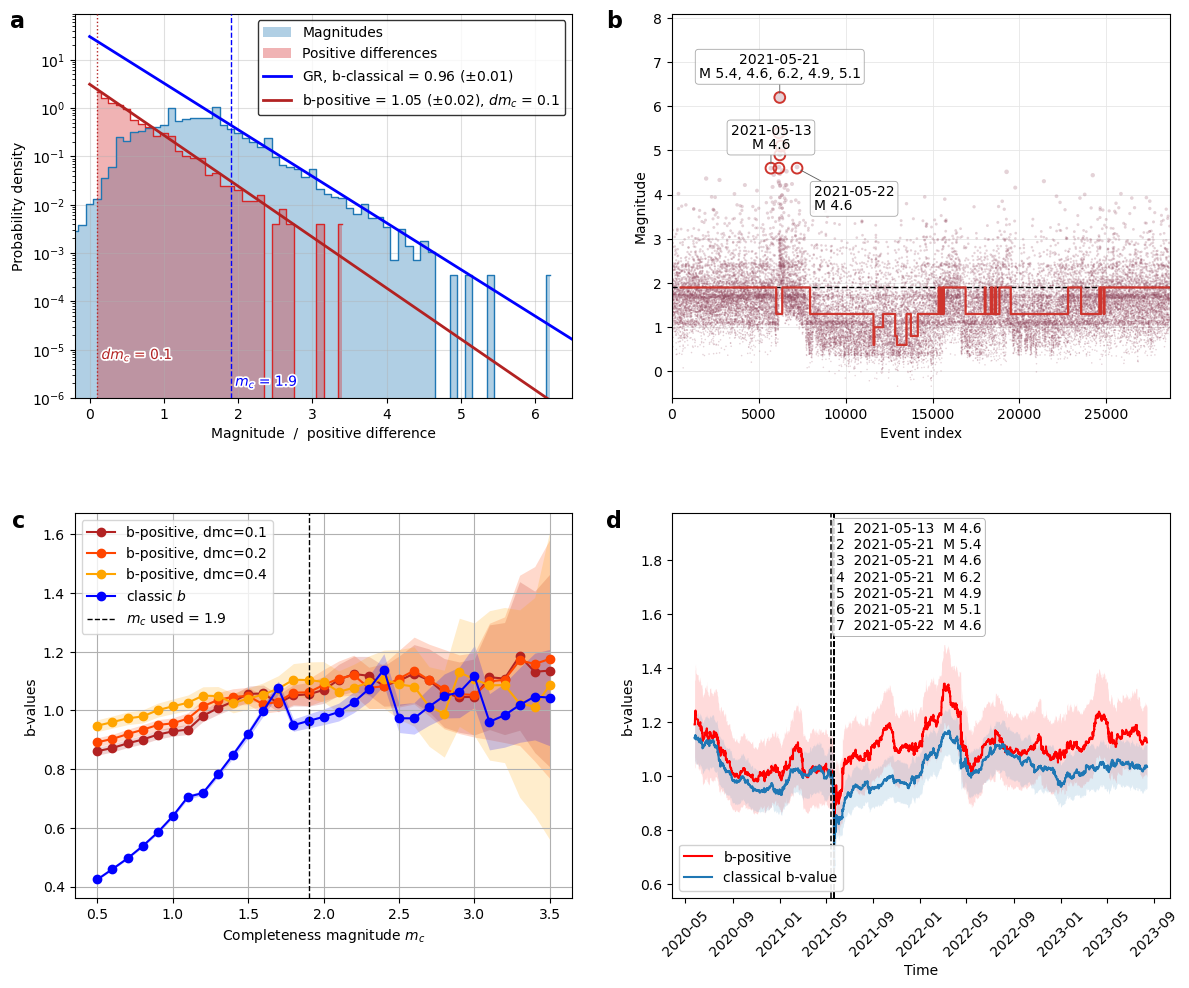

In [11]:
# Regional figure, panels (a)-(d)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from seismostats.analysis import ClassicBValueEstimator, BPositiveBValueEstimator
from seismostats.plots import plot_b_series_constant_nm

label = window_label(cat)
mc = mc_maxc                      # MAXC + 0.2, as in Table S1
delta_m = cat.delta_m
times = cat.time
mags = cat.magnitude
n_m = window_n(cat)               # N of the sliding window (Table S1)
thr = mark_threshold(cat)         # highlighted in (b): M >= 6 (main text) or M >= 7 (SI long windows)
print(label, f'mc = {mc:.1f}', f'N = {n_m}', f'events = {len(cat)}', f'highlight threshold M >= {thr:.0f}')

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# (a) probability densities of the magnitudes and of the positive magnitude differences, with the GR line
#     (b-classical) and the b-positive line (van der Elst 2021, Fig. 5)
plot_density_fmd(axes[0, 0], mags, times, mc, delta_m, b_classical, b_classical_std, b_positive, b_positive_std, dmc=0.1)

# (b) magnitude vs event index with the local Mc
plot_mags_vs_index(axes[0, 1], cat, mc, n_m, thr, windows=ANALYSIS_WINDOWS)

# (c) b-value vs Mc
mcs = np.arange(0.5, 3.6, 0.1)
ax_mc = axes[1, 0]
cat.plot_mc_vs_b(mcs, b_method=BPositiveBValueEstimator, dmc=0.1, ax=ax_mc, color='firebrick', label='b-positive, dmc=0.1')
cat.plot_mc_vs_b(mcs, b_method=BPositiveBValueEstimator, dmc=0.2, ax=ax_mc, color='orangered', label='b-positive, dmc=0.2')
cat.plot_mc_vs_b(mcs, b_method=BPositiveBValueEstimator, dmc=0.4, ax=ax_mc, color='orange', label='b-positive, dmc=0.4')
cat.plot_mc_vs_b(mcs, b_method=ClassicBValueEstimator, ax=ax_mc, color='blue', label='classic $b$')
ax_mc.axvline(mc, color='k', linestyle='--', linewidth=1, label=f'$m_c$ used = {mc:.1f}')
ax_mc.legend()

# (d) b-value series, N events above mc, value plotted at the last event of each window;
#     the five largest events of the window as numbered dashed lines with date / magnitude labels
ax_series = axes[1, 1]
plot_b_series_constant_nm(mags, delta_m, mc, times, n_m=n_m, x_variable=times,
                          color='red', plot_technique='right', label='b-positive',
                          ax=ax_series, b_method=BPositiveBValueEstimator)
plot_b_series_constant_nm(mags, delta_m, mc, times, n_m=n_m, x_variable=times,
                          color='#1f77b4', plot_technique='right', label='classical b-value',
                          ax=ax_series)
y0, y1 = ax_series.get_ylim()
ax_series.set_ylim(y0, y1 + 0.45 * (y1 - y0))          # room for the event labels above the curves
d_jobs = mark_events_in_time(ax_series, times, mags, thr)
ax_series.legend(loc='lower left', framealpha=0.9)
for tl in ax_series.get_xticklabels():
    tl.set_rotation(45)

for i, ax in enumerate(axes.flat):
    ax.text(-0.1, 0.95, 'abcd'[i], transform=ax.transAxes, fontsize=16, fontweight='bold', va='bottom', ha='right')

plt.tight_layout()
plt.subplots_adjust(wspace=0.2, hspace=0.3)
place_event_labels_b(axes[0, 1])              # labels last: positions measured on the final layout
place_event_labels_d(ax_series, d_jobs)
plt.savefig(f'{label}_abcd.pdf')
plt.show()

# numbers of this run (cross-check against Table S1)
numbers, thr_set, top_set = marked_events(mags.values, times.values, thr)
pd.DataFrame([dict(window=label, t_start=cat.time.min().date(), t_end=cat.time.max().date(), n_events=len(cat),
                   mc=round(float(mc), 1), n_m=n_m,
                   b_classical=round(b_classical, 3), b_classical_std=round(b_classical_std, 3),
                   b_positive=round(b_positive, 3), b_positive_std=round(b_positive_std, 3),
                   p_classical=round(p_classic, 3), p_positive=round(p_positive, 3),
                   post_window_star_threshold=thr,
                   marked_cutoff=marked_cutoff(mags.values), n_marked=len(top_set),
                   marked_events_bdf='; '.join(event_lines(mags.values, times.values, numbers, top_set)))]
             ).to_csv(f'{label}_figrun.csv', index=False)


## 5 Spatial b-value maps, panels (e) and (f)

筛选后用于扫描的有效事件库: 5703 个
开始 ZMAP 模式扫描... 网格: (420, 450), 每个点取最近 300 个事件


计算完成。


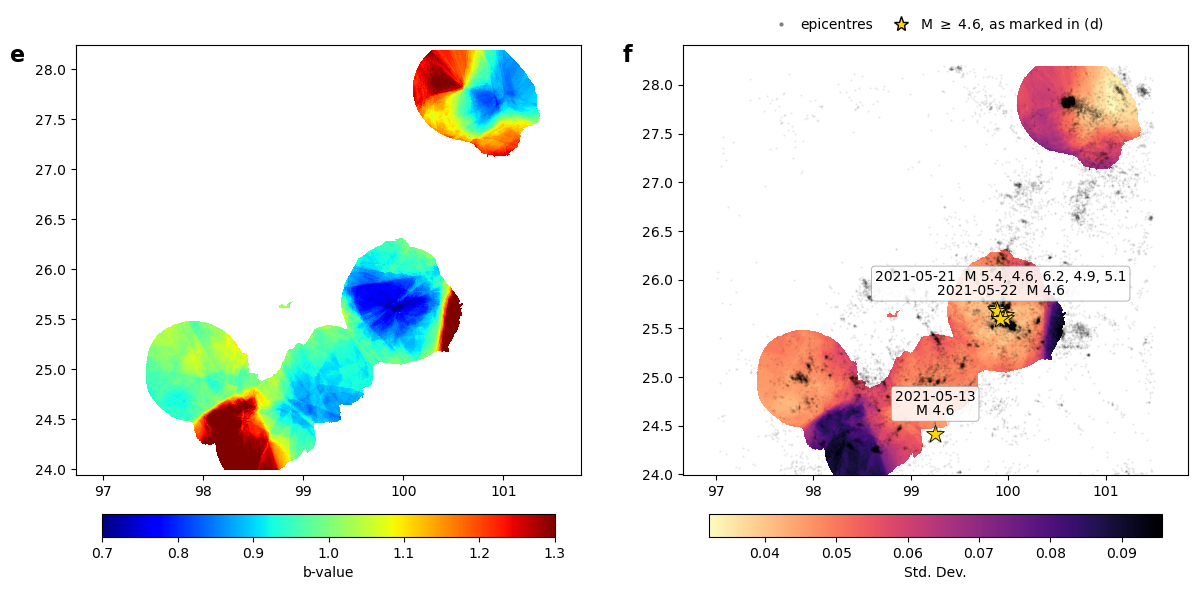

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import copy
from seismostats.analysis import ClassicBValueEstimator, BPositiveBValueEstimator


# 二维 b 值扫描函数 (融合版) =================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import copy

# 假设您已经导入了 ClassicBValueEstimator
# from seismostats.analysis import ClassicBValueEstimator

def spatial_b_value_map_2D(
    lon, 
    lat, 
    mags, 
    grid_size=0.1, 
    n_events=100,      # ZMAP逻辑的核心：目标样本数 N
    max_radius=None,   # 可选：最大搜索半径 (度)，防止连接到几百公里外的地震
    mc=None, 
    delta_m=0.1, 
    b_method=None
):
    """
    【ZMAP 模式】基于最近邻 (Nearest Neighbor) 的移动窗口扫描。
    逻辑：每个网格点强制取最近的 n_events 个地震进行计算。
    """
    # 1. 数据预清洗 (转为 numpy 数组)
    lons_arr = np.array(lon)
    lats_arr = np.array(lat)
    mags_arr = np.array(mags)
    
    valid_mask = ~np.isnan(mags_arr)
    lons_arr = lons_arr[valid_mask]
    lats_arr = lats_arr[valid_mask]
    mags_arr = mags_arr[valid_mask]

    # 2. Mc 筛选
    # ZMAP 逻辑：只对大于 Mc 的“有效地震”进行最近邻搜索
    if mc is not None:
        idx = mags_arr >= (mc - delta_m / 2)
        lons_proc = lons_arr[idx]
        lats_proc = lats_arr[idx]
        mags_proc = mags_arr[idx]
    else:
        lons_proc = lons_arr
        lats_proc = lats_arr
        mags_proc = mags_arr

    total_events = len(mags_proc)
    print(f"筛选后用于扫描的有效事件库: {total_events} 个")
    
    if total_events < n_events:
        print(f"错误：总有效地震数 ({total_events}) 小于目标采样数 ({n_events})，无法计算。")
        return None, None, None, None, None

    # 3. 定义网格 (Grid Nodes)
    x_min, x_max = lons_proc.min(), lons_proc.max()
    y_min, y_max = lats_proc.min(), lats_proc.max()
    
    xi = np.arange(x_min, x_max, grid_size)
    yi = np.arange(y_min, y_max, grid_size)
    X, Y = np.meshgrid(xi, yi)
    
    # 初始化结果矩阵
    B_grid = np.full(X.shape, np.nan)
    Std_grid = np.full(X.shape, np.nan)
    Radius_grid = np.full(X.shape, np.nan) # 新增：记录每个点的搜索半径

    # 初始化估算器
    if b_method is None:
        # 这里请确保 ClassicBValueEstimator 已定义
        # estimator = ClassicBValueEstimator()
        raise ValueError("请传入 b_method 参数 (例如 ClassicBValueEstimator)")
    else:
        estimator = b_method()

    # 4. 空间扫描 (Moving Window)
    print(f"开始 ZMAP 模式扫描... 网格: {X.shape}, 每个点取最近 {n_events} 个事件")
    
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            node_lon = X[i, j]
            node_lat = Y[i, j]
            
            # 计算到所有有效地震的距离平方 (欧氏距离近似)
            # 如果区域很大，建议改为 Haversine
            dists_sq = (lons_proc - node_lon)**2 + (lats_proc - node_lat)**2
            
            # --- ZMAP 核心算法 ---
            # 找到最近的 n_events 个地震的索引
            # argpartition 效率很高，不需要全排序
            nearest_idx_unsorted = np.argpartition(dists_sq, n_events)[:n_events]
            
            # 获取这些地震的距离，找出其中最大的那个作为“分辨率半径”
            current_dists_sq = dists_sq[nearest_idx_unsorted]
            max_dist_sq = np.max(current_dists_sq)
            current_radius_deg = np.sqrt(max_dist_sq)
            
            # 选出的震级
            local_mags = mags_proc[nearest_idx_unsorted]
            
            # --- 额外检查：最大半径限制 ---
            # 如果凑齐 100 个地震需要跑到 500 公里外，这个点的 b 值就没有局部代表性了，设为 NaN
            if max_radius is not None and current_radius_deg > max_radius:
                B_grid[i, j] = np.nan
                continue

            # 计算 b 值
            estimator.calculate(local_mags, mc=mc, delta_m=delta_m)
            
            # 只要 estimator 算出来了，就赋值
            # (通常只要 len(local_mags) > 0 就能算，而这里必定等于 n_events)
            B_grid[i, j] = estimator.b_value
            Std_grid[i, j] = estimator.std
            Radius_grid[i, j] = current_radius_deg

    print("计算完成。")
    return X, Y, B_grid, Std_grid, Radius_grid

# ================= 使用示例 =================

# 设置参数
mc = mc_maxc # chosen magnitude of completeness
delta_m = cat.delta_m # binning of the magnitudes    
N_PER_GRID = 300   
GRID_SIZE = 0.01   
mags = cat.magnitude
longitude = cat.longitude
latitude = cat.latitude


# 执行计算 (假设您已经定义了 ClassicBValueEstimator)
# 如果 ClassicBValueEstimator 在之前的单元格已运行，这里不需要 import
try:
    grid_X, grid_Y, grid_B, grid_Std,grid_R = spatial_b_value_map_2D(
        lon = longitude, 
        lat = latitude,
        mags = mags,
        grid_size=GRID_SIZE, 
        n_events=N_PER_GRID, 
        mc=mc, 
        max_radius=0.5,  # 可选：最大搜索半径 2 度 (~200km)
        delta_m=delta_m,
        b_method=ClassicBValueEstimator # 显式传入方法类
    )

    # 绘图：同时展示 b 值 和 标准差 error
    if grid_B is not None:
        fig, axes = plt.subplots(1, 2, figsize=(12, 6))
        my_cmap = copy.copy(plt.get_cmap('jet'))
    
        # 2. 【核心步骤】设置 NaN 值的颜色
        # 'white' 表示白色，alpha=0 表示完全透明（如果想透出底图）
        # 如果您没有底图，设为 'white' (alpha=1) 也是可以的
        my_cmap.set_bad(color='white')
        # 图 1: b-value
        im1 = axes[0].pcolormesh(grid_X, grid_Y, grid_B, cmap=my_cmap, shading='auto', vmin=0.7, vmax=1.3, rasterized=True)
        plt.colorbar(im1,orientation='horizontal', fraction=0.046, pad=0.08, ax=axes[0], label='b-value')
        # axes[0].set_title(f'Spatial b-value (N={N_PER_GRID})')
        axes[0].axis('equal')

        # 图 2: Standard Deviation
        # std 通常较小，颜色范围可以自动或设为 0 ~ 0.2
        im2 = axes[1].pcolormesh(grid_X, grid_Y, grid_Std, cmap='magma_r', shading='auto', rasterized=True)
        plt.colorbar(im2,orientation='horizontal', fraction=0.046, pad=0.08,ax=axes[1], label='Std. Dev.')
        # axes[1].set_title(f'Standard Deviation of b (N={N_PER_GRID})')
        axes[1].scatter(longitude, latitude, s=0.2, c='k', alpha=0.1, rasterized=True)
        # stars: the events marked in panel (d), labelled with date and magnitude;
        # white stars: M >= threshold (6 main text / 7 SI) after the window, with date and magnitude
        thr = mark_threshold(cat)
        lon_a, lat_a = np.asarray(longitude, float), np.asarray(latitude, float)
        numbers, _, top_set = marked_events(mags.values, cat.time.values, thr)
        axes[1].scatter(lon_a[top_set], lat_a[top_set], s=180, marker='*', fc=C_STAR, ec='k', lw=0.6, zorder=6)
        t_a = cat.time.values
        f_anchors = [(lon_a[i], lat_a[i]) for i in top_set]
        f_events = [(t_a[i], float(mags.values[i])) for i in top_set]
        post = post_window_events(cat, min_mag=thr)
        if len(post):
            axes[1].scatter(post.longitude, post.latitude, s=180, marker='*', fc=C_POST, ec='k', lw=0.9, zorder=6)
            for _, r in post.iterrows():
                f_anchors.append((r.longitude, r.latitude)); f_events.append((r.time, float(r.magnitude)))
        handles = [Line2D([], [], marker='o', ls='', mfc='k', mec='none', ms=3, alpha=0.5, label='epicentres'),
                   Line2D([], [], marker='*', ls='', mfc=C_STAR, mec='k', ms=11, label=f'M $\\geq$ {marked_cutoff(mags.values):.1f}, as marked in (d)')]
        if len(post):
            handles.append(Line2D([], [], marker='*', ls='', mfc=C_POST, mec='k', ms=11,
                                  label=f'M $\\geq$ {thr:.0f} after the window'))
        axes[1].legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=len(handles),
                       frameon=False, columnspacing=1.0, handletextpad=0.4)   # above the map: never covers a star
        axes[1].axis('equal')
        labels = ['e', 'f']

        for i, ax in enumerate(axes.flat):
            ax.text(-0.1, 0.95, labels[i], transform=ax.transAxes,
                fontsize=16, fontweight='bold', va='bottom', ha='right')

        plt.tight_layout()
        plt.subplots_adjust(wspace=0.2, hspace=0.3)
        place_event_labels_f(axes[1], f_anchors, f_events)   # labels last, on the final layout
        plt.savefig(f'{window_label(cat)}_ef.pdf')
        plt.show()

except NameError:
    print("错误: 找不到 ClassicBValueEstimator 类。请确保您已经运行了包含该类定义的代码块。")